# Cross-Dataset Object Detection — Track A

**Models:** YOLO11s, RT-DETR-L, Faster R-CNN ResNet50-FPN v2  
**Datasets:** COCO 2017 validation (5,000 images) and nuImages validation (16,445 images)  
**Shared classes:** person, car, truck, bus, bicycle, motorcycle.

**Recommended for reviewing completed experiments:** Run **Setup**, then **Section 6** and **Section 7**. All full-run predictions, metrics, and configuration files are stored in Google Drive; **do not rerun inference unnecessarily**. Dataset extraction is only needed to display example images or rebuild annotations. To reproduce inference from scratch, follow Sections 1–5 in order with a GPU runtime.

**Important limitations:** These are six-class custom evaluations, not official 80-class COCO scores. Cross-dataset changes combine domain and annotation-policy differences. Model input preprocessing differs (Ultralytics 640-pixel letterbox versus Torchvision native resizing).

## Setup — Dependencies, Drive, and experiment configuration

In [ ]:
%pip install -q "ultralytics>=8.3,<9" "pycocotools>=2.0.7" pandas matplotlib pillow tqdm

In [ ]:
import os, sys, json, time, random, gc, platform, subprocess, urllib.request, zipfile
from pathlib import Path
import numpy as np, pandas as pd, torch, torchvision
from PIL import Image
from tqdm.auto import tqdm
from google.colab import drive
from ultralytics import YOLO, RTDETR
from torchvision.models.detection import fasterrcnn_resnet50_fpn_v2, FasterRCNN_ResNet50_FPN_V2_Weights
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval

drive.mount('/content/drive')
ROOT = Path('/content/drive/MyDrive/ColabNotebooks/detection_benchmark')
ROOT.mkdir(parents=True, exist_ok=True)
COCO_DIR = Path('/content/datasets/coco')
#NUIMAGES_ROOT = Path('/content/drive/MyDrive/ColabNotebooks/nuimages') # CHANGE if necessary
NUIMAGES_ROOT = Path('/content/datasets/nuimages')
PILOT = False
PILOT_COCO_IMAGES = 100
PILOT_NUIMAGES_IMAGES = 100
SEED = 42
CONF = 0.001 # low threshold for AP/AR evaluation; do NOT use 0.25
IOU_NMS = 0.7
IMG_SIZE = 640
MAX_DETS = 100
random.seed(SEED); np.random.seed(SEED)
assert torch.cuda.is_available(), 'Select a GPU runtime in Colab.'
DEVICE = 'cuda:0'
print('GPU:', torch.cuda.get_device_name(0))
print('Torch:', torch.__version__, 'Torchvision:', torchvision.__version__)
print('Python:', platform.python_version())


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Mounted at /content/drive
GPU: NVIDIA RTX PRO 6000 Blackwell Server Edition
Torch: 2.11.0+cu130 Torchvision: 0.26.0+cu130
Python: 3.13.16


## 1. COCO validation data (only if local data is missing)

The saved six-class ground-truth JSON can be reused without downloading COCO. Run the download cell only when rebuilding the dataset or visualizing COCO images after a runtime reset.

In [ ]:

from pathlib import Path
import subprocess
import zipfile

COCO_DIR = Path("/content/datasets/coco")
COCO_DIR.mkdir(parents=True, exist_ok=True)

downloads = {
    "val2017.zip": (
        "http://images.cocodataset.org/zips/val2017.zip",
        COCO_DIR / "val2017"
    ),
    "annotations_trainval2017.zip": (
        "http://images.cocodataset.org/annotations/annotations_trainval2017.zip",
        COCO_DIR / "annotations/instances_val2017.json"
    )
}

for filename, (url, expected_path) in downloads.items():
    target = COCO_DIR / filename

    if not expected_path.exists():
        if not target.exists():
            print(f"Downloading {filename}...")

            subprocess.run(
                [
                    "wget",
                    "--tries=3",
                    "--timeout=60",
                    "-O", str(target),
                    url
                ],
                check=True
            )

        if not zipfile.is_zipfile(target):
            target.unlink(missing_ok=True)
            raise RuntimeError(
                f"{filename} is not a valid ZIP file. "
                "The download endpoint may be unavailable."
            )

        print(f"Extracting {filename}...")

        with zipfile.ZipFile(target) as z:
            z.extractall(COCO_DIR)

    print(f"{filename}: Ready")

print("\nCOCO dataset preparation complete.")


## 2. Shared six-class taxonomy and COCO ground truth

In [ ]:
# ============================================================
# SECTION 2: COMMON CLASS TAXONOMY
# ============================================================

from pycocotools.coco import COCO as COCOApi

# Six shared object classes for COCO and nuImages
CLASSES = [
    'person',
    'car',
    'truck',
    'bus',
    'bicycle',
    'motorcycle'
]

# Shared category IDs (1 through 6)
NAME_TO_ID = {
    name: i + 1
    for i, name in enumerate(CLASSES)
}

# Load original COCO validation annotations
coco_dataset = COCOApi(
    str(COCO_DIR / 'annotations' / 'instances_val2017.json')
)

# Original COCO class name -> category ID
COCO_NAME_TO_ID = {
    c['name']: c['id']
    for c in coco_dataset.dataset['categories']
}

# Select the six classes from the original COCO taxonomy
selected = [
    COCO_NAME_TO_ID[name]
    for name in CLASSES
]

# Map original COCO category IDs to shared category IDs
COCO_OLD_TO_NEW = {
    COCO_NAME_TO_ID[name]: NAME_TO_ID[name]
    for name in CLASSES
}


def make_coco_gt(coco, image_ids):
    """
    Create COCO-format ground truth using only the six
    shared object classes.

    Preserves original images and bounding boxes while
    remapping category IDs to the shared taxonomy.
    """

    # Convert once for efficient membership checking
    image_id_set = set(image_ids)

    # Preserve original image records
    images = [
        dict(coco.imgs[image_id])
        for image_id in image_ids
    ]

    # Filter annotations and remap category IDs
    annotations = []

    for annotation in coco.dataset['annotations']:
        if (
            annotation['image_id'] in image_id_set
            and annotation['category_id'] in COCO_OLD_TO_NEW
        ):
            new_annotation = dict(annotation)

            new_annotation['category_id'] = (
                COCO_OLD_TO_NEW[annotation['category_id']]
            )

            annotations.append(new_annotation)

    # Define shared categories
    categories = [
        {
            'id': NAME_TO_ID[name],
            'name': name,
            'supercategory': 'object'
        }
        for name in CLASSES
    ]

    return {
        'info': {
            'description': 'COCO 2017 shared-six-class evaluation'
        },
        'licenses': [],
        'images': images,
        'annotations': annotations,
        'categories': categories
    }


# ============================================================
# SELECT EVALUATION IMAGES
# ============================================================

# All COCO validation image IDs
coco_ids = sorted(coco_dataset.getImgIds())

# Use a reproducible subset only during pilot evaluation
if PILOT:
    coco_ids = random.Random(SEED).sample(
        coco_ids,
        min(PILOT_COCO_IMAGES, len(coco_ids))
    )

# Generate shared-class ground truth
coco_gt = make_coco_gt(coco_dataset, coco_ids)

# Separate files for pilot and full evaluation
COCO_GT_PATH = ROOT / (
    'coco_gt_pilot.json'
    if PILOT
    else 'coco_gt_full.json'
)

# Save ground-truth annotations
if COCO_GT_PATH.exists():
    print('Preserving existing COCO ground truth:', COCO_GT_PATH)
else:
    COCO_GT_PATH.write_text(json.dumps(coco_gt))

# ============================================================
# VERIFICATION
# ============================================================

print('\nCOCO ground truth prepared successfully!')
print('Evaluation mode:', 'PILOT' if PILOT else 'FULL')
print('Images:', len(coco_gt['images']))
print('Annotations:', len(coco_gt['annotations']))
print('Classes:', CLASSES)
print('Ground-truth file:', COCO_GT_PATH)

## 3. nuImages dataset and taxonomy conversion

The official nuImages archives must already be in `MyDrive/ColabNotebooks/nuimages`. **Run extraction only if the local `/content/datasets/nuimages` folder is missing.** The conversion uses the explicit class mapping below; excluded categories are not treated as official ignore regions. Existing full ground-truth files are preserved to keep saved prediction evaluations consistent.

In [ ]:
# ============================================================
# SECTION 3A: EXTRACT NUIMAGES DATASET
# ============================================================

from pathlib import Path
import subprocess
import shutil

# Archives stored in Google Drive
NUIMAGES_ARCHIVES = Path(
    '/content/drive/MyDrive/ColabNotebooks/nuimages'
)

# Extracted dataset stored locally for faster evaluation
NUIMAGES_ROOT = Path('/content/datasets/nuimages')
NUIMAGES_ROOT.mkdir(parents=True, exist_ok=True)

metadata_archive = (
    NUIMAGES_ARCHIVES / 'nuimages-v1.0-all-metadata.tgz'
)

samples_archive = (
    NUIMAGES_ARCHIVES / 'nuimages-v1.0-all-samples.tgz'
)

# Verify both archives exist
assert metadata_archive.exists(), "Metadata archive not found."
assert samples_archive.exists(), "Samples archive not found."

# Check available local storage
total, used, free = shutil.disk_usage('/content')
print(f"Available local storage: {free / 1024**3:.2f} GB")

# Check archive contents before extracting
for archive in [metadata_archive, samples_archive]:
    print(f"\nArchive: {archive.name}")
    subprocess.run(
        ['tar', '-tzf', str(archive)],
        stdout=subprocess.DEVNULL,
        check=True
    )

# Extract metadata
if not (NUIMAGES_ROOT / 'v1.0-val').exists():
    print("\nExtracting nuImages metadata...")
    subprocess.run(
        ['tar', '-xzf', str(metadata_archive),
         '-C', str(NUIMAGES_ROOT)],
        check=True
    )
else:
    print("Metadata already extracted.")

# Extract camera samples
if not (NUIMAGES_ROOT / 'samples').exists():
    print("\nExtracting nuImages camera samples...")
    subprocess.run(
        ['tar', '-xzf', str(samples_archive),
         '-C', str(NUIMAGES_ROOT)],
        check=True
    )
else:
    print("Camera samples already extracted.")

print("\nExtraction completed!")
print("Dataset root:", NUIMAGES_ROOT)

In [ ]:
# ============================================================
# SECTION 3D: CONVERT NUIMAGES TO COCO FORMAT
# ============================================================

import json
from pathlib import Path
from collections import Counter

VAL_DIR = NUIMAGES_ROOT / 'v1.0-val'

# Reuse shared taxonomy from Section 2
assert 'NAME_TO_ID' in globals(), "Run Section 2 first."

def load_nu_table(name):
    with open(VAL_DIR / f'{name}.json', 'r') as f:
        return json.load(f)

categories = load_nu_table('category')
sample_data = load_nu_table('sample_data')
object_anns = load_nu_table('object_ann')

# nuImages category -> shared class
NU_CATEGORY_TO_CLASS = {
    'human.pedestrian.adult': 'person',
    'human.pedestrian.child': 'person',
    'human.pedestrian.construction_worker': 'person',
    'human.pedestrian.police_officer': 'person',

    'vehicle.car': 'car',
    'vehicle.truck': 'truck',
    'vehicle.bus.bendy': 'bus',
    'vehicle.bus.rigid': 'bus',
    'vehicle.bicycle': 'bicycle',
    'vehicle.motorcycle': 'motorcycle',
}

category_by_token = {
    c['token']: c['name']
    for c in categories
}

# Select annotated keyframes
keyframes = [
    sd for sd in sample_data
    if sd.get('is_key_frame', False)
]

# Use deterministic ordering
keyframes = sorted(keyframes, key=lambda x: x['token'])

# Optional pilot subset
if PILOT:
    rng = random.Random(SEED)
    keyframes = rng.sample(
        keyframes,
        min(PILOT_NUIMAGES_IMAGES, len(keyframes))
    )

# Assign stable integer image IDs
token_to_image_id = {
    sd['token']: i + 1
    for i, sd in enumerate(keyframes)
}

images = []
missing_files = []

for sd in keyframes:
    image_path = NUIMAGES_ROOT / sd['filename']

    if not image_path.is_file():
        missing_files.append(sd['filename'])
        continue

    images.append({
        'id': token_to_image_id[sd['token']],
        'file_name': sd['filename'],
        'width': sd['width'],
        'height': sd['height']
    })

if missing_files:
    raise FileNotFoundError(
        f"{len(missing_files)} keyframe images are missing. "
        f"Example: {missing_files[:3]}"
    )

# Convert bounding-box annotations
annotations = []
class_counts = Counter()
annotation_id = 1

for ann in object_anns:
    sample_token = ann['sample_data_token']

    if sample_token not in token_to_image_id:
        continue

    category_name = category_by_token[ann['category_token']]
    shared_name = NU_CATEGORY_TO_CLASS.get(category_name)

    if shared_name is None:
        continue

    x1, y1, x2, y2 = map(float, ann['bbox'])

    width = x2 - x1
    height = y2 - y1

    if width <= 0 or height <= 0:
        continue

    annotations.append({
        'id': annotation_id,
        'image_id': token_to_image_id[sample_token],
        'category_id': NAME_TO_ID[shared_name],
        'bbox': [x1, y1, width, height],
        'area': width * height,
        'iscrowd': 0
    })

    class_counts[shared_name] += 1
    annotation_id += 1

# COCO-format ground truth
nu_gt = {
    'info': {
        'description': 'nuImages validation shared-six-class evaluation'
    },
    'licenses': [],
    'images': images,
    'annotations': annotations,
    'categories': [
        {
            'id': NAME_TO_ID[name],
            'name': name,
            'supercategory': 'object'
        }
        for name in CLASSES
    ]
}

# Save converted annotations to Drive
NU_GT_PATH = ROOT / (
    'nuimages_gt_pilot.json'
    if PILOT
    else 'nuimages_gt_full.json'
)

if NU_GT_PATH.exists():
    print('Preserving existing nuImages ground truth:', NU_GT_PATH)
else:
    NU_GT_PATH.write_text(json.dumps(nu_gt))

print("\nnuImages conversion completed!")
print("Mode:", "PILOT" if PILOT else "FULL")
print("Images:", len(images))
print("Annotations:", len(annotations))
print("Ground truth:", NU_GT_PATH)

print("\nAnnotations per class:")
for name in CLASSES:
    print(f"  {name}: {class_counts[name]:,}")

# Verify generated JSON can be read by COCO API
from pycocotools.coco import COCO as COCOApi

nu_coco = COCOApi(str(NU_GT_PATH))

assert len(nu_coco.getImgIds()) > 0
assert len(nu_coco.getCatIds()) == len(CLASSES)

print("\nCOCO API validation: PASSED")

## 4. Model inference wrappers and COCO-style metrics

All models use batch size 1, confidence cutoff 0.001, and at most 100 detections per image. Faster R-CNN uses its checkpoint-native image transform. The low confidence cutoff is intentional for AP evaluation.

In [ ]:
TORCH_WEIGHTS = FasterRCNN_ResNet50_FPN_V2_Weights.COCO_V1
TORCH_NAMES = TORCH_WEIGHTS.meta['categories']
MODEL_SPECS = {
 'yolo11s': {'family':'YOLO','checkpoint':'yolo11s.pt'},
 'rtdetr-l': {'family':'RT-DETR','checkpoint':'rtdetr-l.pt'},
 'fasterrcnn-r50-fpn-v2': {'family':'Faster R-CNN','checkpoint':'FasterRCNN_ResNet50_FPN_V2_Weights.COCO_V1'},
}

def create_model(key):
    if key=='yolo11s': return YOLO('yolo11s.pt')
    if key=='rtdetr-l': return RTDETR('rtdetr-l.pt')
    return fasterrcnn_resnet50_fpn_v2(weights=TORCH_WEIGHTS).to(DEVICE).eval()

def predict(model, key, pil_image):
    if key != 'fasterrcnn-r50-fpn-v2':
        out=model.predict(source=np.array(pil_image), device=0, imgsz=IMG_SIZE,
                          conf=CONF, iou=IOU_NMS, max_det=MAX_DETS, verbose=False)[0]
        boxes=out.boxes
        xyxy=boxes.xyxy.cpu().numpy(); scores=boxes.conf.cpu().numpy()
        names=[model.names[int(i)] for i in boxes.cls.cpu().numpy()]
    else:
        from torchvision.transforms.functional import to_tensor
        tensor=to_tensor(pil_image).to(DEVICE)
        with torch.inference_mode(): result=model([tensor])[0]
        xyxy=result['boxes'].cpu().numpy()
        scores=result['scores'].cpu().numpy()
        names=[TORCH_NAMES[int(i)] for i in result['labels'].cpu().numpy()]
    detections=[]
    for box,score,name in zip(xyxy,scores,names):
        if name not in NAME_TO_ID or float(score)<CONF: continue
        x1,y1,x2,y2=map(float,box)
        if x2<=x1 or y2<=y1: continue
        detections.append({'category_id':NAME_TO_ID[name], 'bbox':[x1,y1,x2-x1,y2-y1],
                           'score':float(score)})
    return sorted(detections,key=lambda x:x['score'],reverse=True)[:MAX_DETS]

def evaluate(gt_path,pred_path):
    gt=COCOApi(str(gt_path))
    predictions=json.loads(Path(pred_path).read_text())
    if not predictions:
        print('No predictions; returning NaN metrics')
        return {x:float('nan') for x in ['mAP','AP50','AP75','AP_small','AP_medium','AP_large','AR100']}, {}
    dt=gt.loadRes(str(pred_path))
    ev=COCOeval(gt,dt,'bbox')
    ev.params.catIds=list(NAME_TO_ID.values())
    ev.params.imgIds=sorted(gt.getImgIds())
    ev.params.maxDets=[1,10,100]
    ev.evaluate(); ev.accumulate(); ev.summarize()
    labels=['mAP','AP50','AP75','AP_small','AP_medium','AP_large']
    metrics={k:float(ev.stats[i]) for i,k in enumerate(labels)}
    metrics['AR100']=float(ev.stats[8])
    precision=ev.eval['precision'] # T x R x K x A x M
    per_class={}
    for idx,name in enumerate(CLASSES):
        vals=precision[:,:,idx,0,2]
        valid=vals[vals>-1]
        per_class[name]=float(valid.mean()) if len(valid) else float('nan')
    return metrics,per_class


## 5. Full inference and evaluation — optional

**Do not run this section when only analyzing existing results.** Set `RUN_INFERENCE = True` deliberately to enable it. The existing inference cell evaluates **nuImages only**; the completed COCO results are already stored in `full_summary.csv` and `full_per_class_ap.csv`. Saved nuImages predictions and timing are reused when their fingerprints match.

In [ ]:
RUN_INFERENCE = False  # Set True only when you intentionally want to run Section 5

In [ ]:
if not RUN_INFERENCE:
    print('Section 5 skipped: using saved full experiment outputs.')
else:

    # ============================================================
    # SECTION 5: MODEL EVALUATION — NUIMAGES
    # ============================================================

    import json
    import time
    import gc
    import platform
    import hashlib
    from pathlib import Path

    import numpy as np
    import pandas as pd
    import torch
    import ultralytics

    from PIL import Image
    from tqdm.auto import tqdm

    # ------------------------------------------------------------
    # 1. Evaluation configuration
    # ------------------------------------------------------------

    RUN_TAG = 'pilot' if PILOT else 'full'

    # Evaluate nuImages only
    DATASETS = {
        'nuimages': (NU_GT_PATH, NUIMAGES_ROOT)
    }

    assert NU_GT_PATH.exists(), "nuImages ground truth not found."
    assert NUIMAGES_ROOT.exists(), "nuImages image directory not found."
    assert torch.cuda.is_available(), "GPU is required."

    RESULTS = []
    PER_CLASS = []

    # ------------------------------------------------------------
    # 2. Evaluate each model
    # ------------------------------------------------------------

    for key in MODEL_SPECS:

        print(f"\n{'=' * 60}")
        print("MODEL:", key)
        print(f"{'=' * 60}")

        model = create_model(key)

        for ds, (gt_path, image_root) in DATASETS.items():

            gt_path = Path(gt_path)
            image_root = Path(image_root)

            gt_bytes = gt_path.read_bytes()
            gt_data = json.loads(gt_bytes)

            gt_hash = hashlib.sha256(gt_bytes).hexdigest()

            pred_path = ROOT / (
                f'{RUN_TAG}_{ds}_{key}_predictions.json'
            )

            timing_path = ROOT / (
                f'{RUN_TAG}_{ds}_{key}_timing.json'
            )

            config_path = ROOT / (
                f'{RUN_TAG}_{ds}_{key}_config.json'
            )

            expected_ids = {
                img['id'] for img in gt_data['images']
            }

            latencies = []
            peak_mb = float('nan')

            # ----------------------------------------------------
            # 3. Check whether previous results can be reused
            # ----------------------------------------------------

            reuse_predictions = False

            if pred_path.exists() and timing_path.exists():

                try:
                    timing_data = json.loads(
                        timing_path.read_text()
                    )

                    saved_preds = json.loads(
                        pred_path.read_text()
                    )

                    predicted_ids = {
                        p['image_id'] for p in saved_preds
                    }

                    same_ground_truth = (
                        timing_data.get('gt_sha256') == gt_hash
                    )

                    same_model = (
                        timing_data.get('model') == key
                    )

                    same_image_count = (
                        timing_data.get('num_images')
                        == len(gt_data['images'])
                    )

                    same_settings = (
                        timing_data.get('conf') == CONF
                        and timing_data.get('img_size') == IMG_SIZE
                        and timing_data.get('max_dets') == MAX_DETS
                        and timing_data.get('iou_nms') == IOU_NMS
                    )

                    valid_prediction_ids = (
                        predicted_ids.issubset(expected_ids)
                    )

                    reuse_predictions = all([
                        same_ground_truth,
                        same_model,
                        same_image_count,
                        same_settings,
                        valid_prediction_ids
                    ])

                    if reuse_predictions:
                        print(
                            "Reusing verified predictions:",
                            pred_path.name
                        )

                        latencies = timing_data['latencies_ms']
                        peak_mb = timing_data['peak_gpu_mb']

                    else:
                        print(
                            "Saved results do not match current "
                            "evaluation. Regenerating."
                        )

                except Exception as e:
                    print(
                        "Could not validate saved predictions:",
                        e
                    )
                    print("Regenerating predictions.")

            # ----------------------------------------------------
            # 4. Run inference if needed
            # ----------------------------------------------------

            if not reuse_predictions:

                print(
                    f"Running inference on "
                    f"{len(gt_data['images']):,} images..."
                )

                # Warm up model
                first = gt_data['images'][0]

                with Image.open(
                    image_root / first['file_name']
                ) as im:
                    warm = im.convert('RGB')

                for _ in range(3):
                    predict(model, key, warm)

                torch.cuda.synchronize()
                torch.cuda.reset_peak_memory_stats()

                preds = []

                for rec in tqdm(
                    gt_data['images'],
                    desc=f'{ds}/{key}'
                ):

                    image_path = image_root / rec['file_name']

                    with Image.open(image_path) as im:
                        rgb = im.convert('RGB')

                    torch.cuda.synchronize()

                    start = time.perf_counter()

                    ds_preds = predict(
                        model, key, rgb
                    )

                    torch.cuda.synchronize()

                    elapsed_ms = (
                        time.perf_counter() - start
                    ) * 1000

                    latencies.append(elapsed_ms)

                    for p in ds_preds:
                        preds.append({
                            'image_id': rec['id'],
                            **p
                        })

                peak_mb = (
                    torch.cuda.max_memory_allocated()
                    / 1024**2
                )

                # Save predictions
                pred_path.write_text(
                    json.dumps(preds)
                )

                # Save timing data and dataset fingerprint
                timing_data = {
                    'model': key,
                    'dataset': ds,
                    'num_images': len(gt_data['images']),
                    'gt_sha256': gt_hash,
                    'conf': CONF,
                    'img_size': IMG_SIZE,
                    'max_dets': MAX_DETS,
                    'iou_nms': IOU_NMS,
                    'latencies_ms': latencies,
                    'peak_gpu_mb': peak_mb
                }

                timing_path.write_text(
                    json.dumps(timing_data, indent=2)
                )

                print("Predictions saved:", pred_path.name)
                print("Timing saved:", timing_path.name)

            # ----------------------------------------------------
            # 5. COCO evaluation
            # ----------------------------------------------------

            metrics, per_class = evaluate(
                gt_path,
                pred_path
            )

            median_latency = (
                float(np.median(latencies))
                if latencies else float('nan')
            )

            p95_latency = (
                float(np.percentile(latencies, 95))
                if latencies else float('nan')
            )

            fps = (
                float(1000 / median_latency)
                if median_latency > 0
                else float('nan')
            )

            record = {
                'dataset': ds,
                'model': key,
                'family': MODEL_SPECS[key]['family'],
                'images': len(gt_data['images']),
                **metrics,
                'latency_ms_median': median_latency,
                'latency_ms_p95': p95_latency,
                'fps_from_median': fps,
                'peak_allocated_gpu_mb': peak_mb
            }

            RESULTS.append(record)

            PER_CLASS.extend([
                {
                    'dataset': ds,
                    'model': key,
                    'class': class_name,
                    'AP': ap
                }
                for class_name, ap in per_class.items()
            ])

            # ----------------------------------------------------
            # 6. Save reproducibility configuration
            # ----------------------------------------------------

            config = {
                'model': key,
                **MODEL_SPECS[key],
                'dataset': ds,
                'split': 'val',
                'ground_truth': str(gt_path),
                'ground_truth_sha256': gt_hash,
                'predictions': str(pred_path),
                'num_images': len(gt_data['images']),
                'seed': SEED,
                'pilot': PILOT,
                'imgsz_ultralytics': (
                    IMG_SIZE
                    if key != 'fasterrcnn-r50-fpn-v2'
                    else None
                ),
                'fasterrcnn_resize': (
                    'Torchvision checkpoint native transform '
                    '(min 800, max 1333)'
                ),
                'conf': CONF,
                'nms_iou_yolo': (
                    IOU_NMS if key == 'yolo11s' else None
                ),
                'nms_iou_rtdetr': 'not applicable',
                'nms_iou_fasterrcnn': (
                    'Torchvision internal RPN/ROI defaults'
                ),
                'max_detections': MAX_DETS,
                'batch_size': 1,
                'device': torch.cuda.get_device_name(0),
                'torch': torch.__version__,
                'torchvision': torchvision.__version__,
                'ultralytics': ultralytics.__version__,
                'python': platform.python_version()
            }

            config_path.write_text(
                json.dumps(config, indent=2)
            )

            # Save intermediate results after each model
            pd.DataFrame(RESULTS).to_csv(
                ROOT / f'{RUN_TAG}_{ds}_summary.csv',
                index=False
            )

            pd.DataFrame(PER_CLASS).to_csv(
                ROOT / f'{RUN_TAG}_{ds}_per_class_ap.csv',
                index=False
            )

            print(f"\nCompleted: {key} on {ds}")
            print(f"mAP: {metrics['mAP']:.4f}")
            print(f"Median latency: {median_latency:.2f} ms")

        # Release GPU memory before next model
        del model
        gc.collect()
        torch.cuda.empty_cache()

    # ------------------------------------------------------------
    # 7. Final results
    # ------------------------------------------------------------

    summary = pd.DataFrame(RESULTS)
    perclass = pd.DataFrame(PER_CLASS)

    print("\nFULL EVALUATION COMPLETE")

    display(summary.round(3))

    display(
        perclass.pivot_table(
            index=['dataset', 'class'],
            columns='model',
            values='AP'
        ).round(3)
    )

    print("\nResults saved to:", ROOT)

## 6. Quantitative cross-dataset comparison

Reads the **saved full-run CSVs** from Drive; no inference is performed. Outputs combined tables, mAP changes, per-class comparisons, latency–accuracy plots, and allocated-GPU-memory plots. Note that latency was measured in separate runs, so cross-dataset speed differences may reflect different runtime or image conditions.

Combined full evaluation results:


,dataset,model,family,images,mAP,AP50,AP75,AP_small,AP_medium,AP_large,AR100,latency_ms_median,latency_ms_p95,fps_from_median,peak_allocated_gpu_mb
0,coco,yolo11s,YOLO,5000,0.466,0.653,0.500,0.218,0.493,0.708,0.598,14.125,16.161,70.798,111.570
1,coco,rtdetr-l,RT-DETR,5000,0.537,0.749,0.570,0.309,0.566,0.767,0.682,45.126,48.685,22.160,243.374
2,coco,fasterrcnn-r50-fpn-v2,Faster R-CNN,5000,0.519,0.765,0.558,0.347,0.538,0.692,0.638,25.765,27.798,38.813,695.825
3,nuimages,yolo11s,YOLO,16445,0.225,0.365,0.215,0.021,0.141,0.467,0.346,5.688,5.876,175.812,146.555
4,nuimages,rtdetr-l,RT-DETR,16445,0.288,0.477,0.272,0.060,0.217,0.514,0.460,16.329,16.540,61.240,285.050
5,nuimages,fasterrcnn-r50-fpn-v2,Faster R-CNN,16445,0.319,0.551,0.303,0.109,0.265,0.504,0.454,23.133,23.293,43.229,1602.836


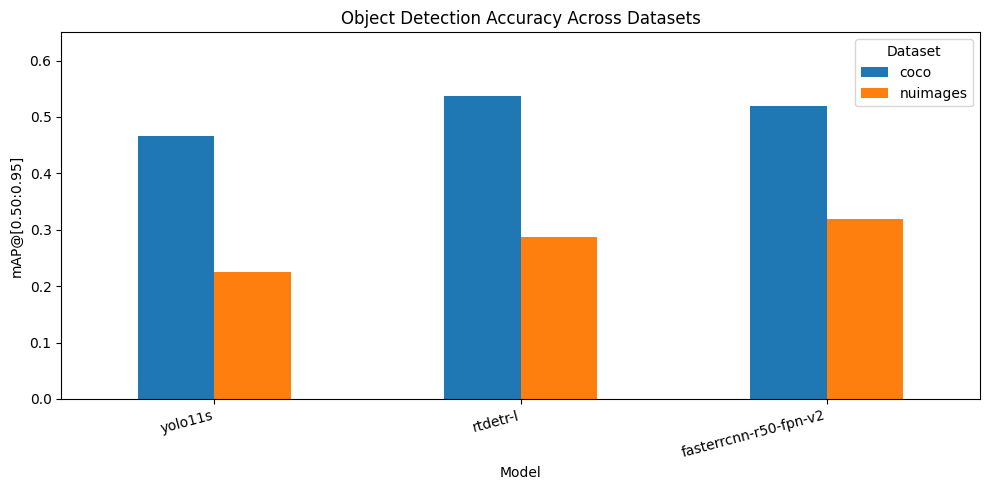


Cross-dataset mAP changes:


dataset,coco,nuimages,absolute_change,relative_change_pct
model,,,,
yolo11s,0.466,0.225,-0.242,-51.830
rtdetr-l,0.537,0.288,-0.250,-46.469
fasterrcnn-r50-fpn-v2,0.519,0.319,-0.199,-38.449



Per-class cross-dataset AP changes:


dataset                            coco  nuimages  absolute_change  \
model                 class                                          
yolo11s               bus         0.691     0.238           -0.453   
rtdetr-l              bus         0.736     0.338           -0.398   
                      person      0.605     0.227           -0.378   
yolo11s               person      0.556     0.182           -0.375   
fasterrcnn-r50-fpn-v2 bus         0.711     0.359           -0.351   
rtdetr-l              motorcycle  0.555     0.218           -0.337   
yolo11s               motorcycle  0.475     0.172           -0.303   
fasterrcnn-r50-fpn-v2 person      0.595     0.300           -0.294   
                      motorcycle  0.503     0.231           -0.272   
rtdetr-l              truck       0.457     0.273           -0.184   
                      bicycle     0.382     0.238           -0.144   
yolo11s               truck       0.345     0.210           -0.135   
                      bicycle     0.325     0.193           -0.133   
fasterrcnn-r50-fpn-v2 bicycle     0.383     0.258           -0.125   
                      truck       0.424     0.326           -0.098   
rtdetr-l              car         0.489     0.432           -0.057   
fasterrcnn-r50-fpn-v2 car         0.497     0.441           -0.056   
yolo11s               car         0.405     0.353           -0.051   

dataset                           relative_change_pct  
model                 class                            
yolo11s               bus                     -65.566  
rtdetr-l              bus                     -54.121  
                      person                  -62.532  
yolo11s               person                  -67.332  
fasterrcnn-r50-fpn-v2 bus                     -49.452  
rtdetr-l              motorcycle              -60.649  
yolo11s               motorcycle              -63.827  
fasterrcnn-r50-fpn-v2 person                  -49.478  
                      motorcycle              -54.071  
rtdetr-l              truck                   -40.264  
                      bicycle                 -37.623  
yolo11s               truck                   -39.127  
                      bicycle                 -40.836  
fasterrcnn-r50-fpn-v2 bicycle                 -32.601  
                      truck                   -23.094  
rtdetr-l              car                     -11.724  
fasterrcnn-r50-fpn-v2 car                     -11.335  
yolo11s               car                     -12.681

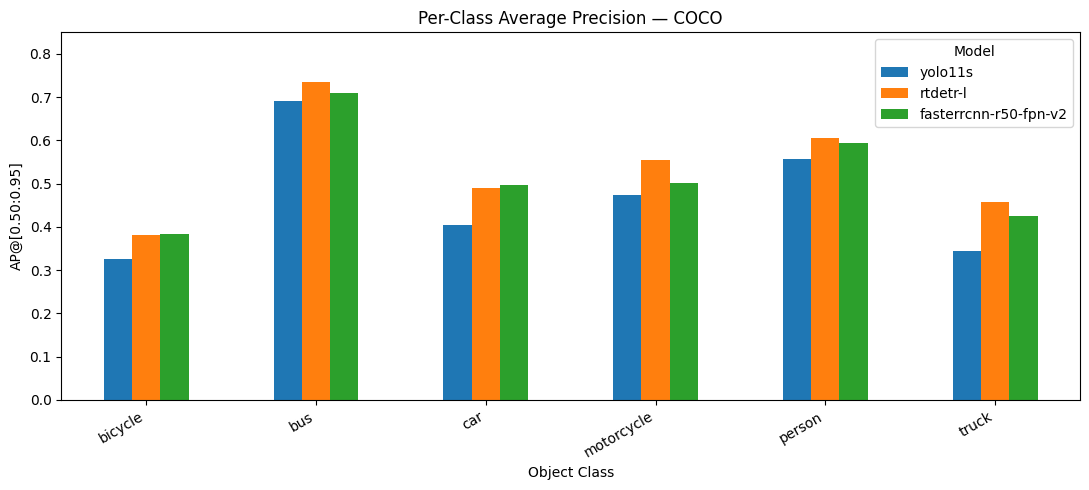

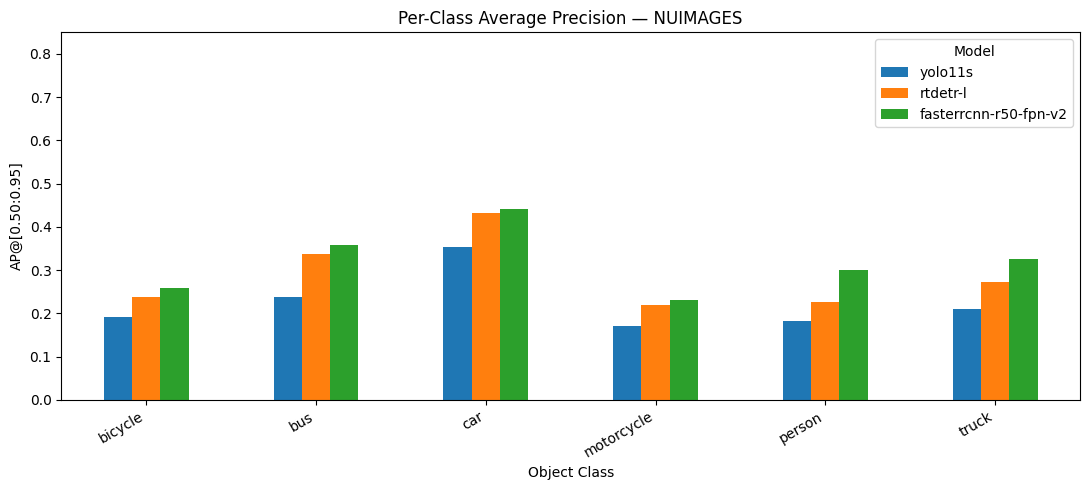

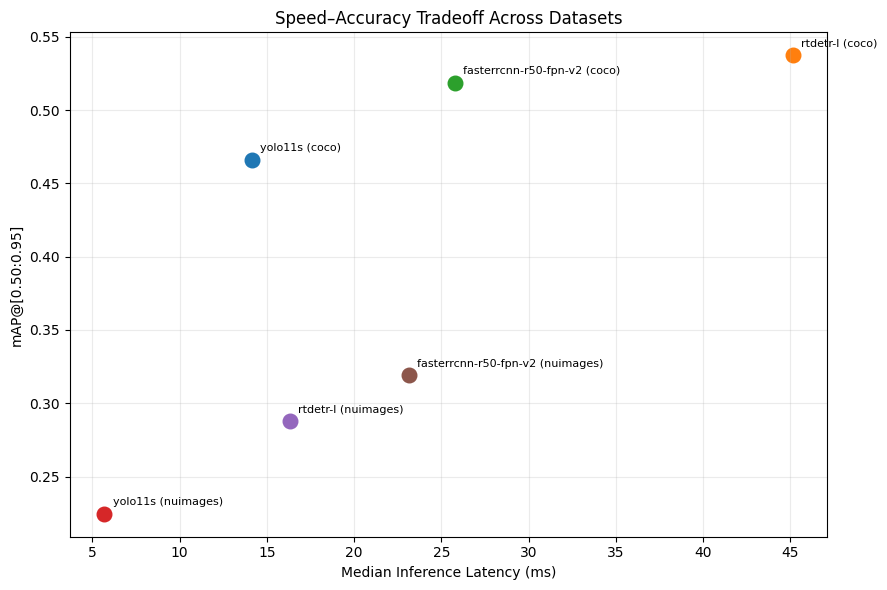

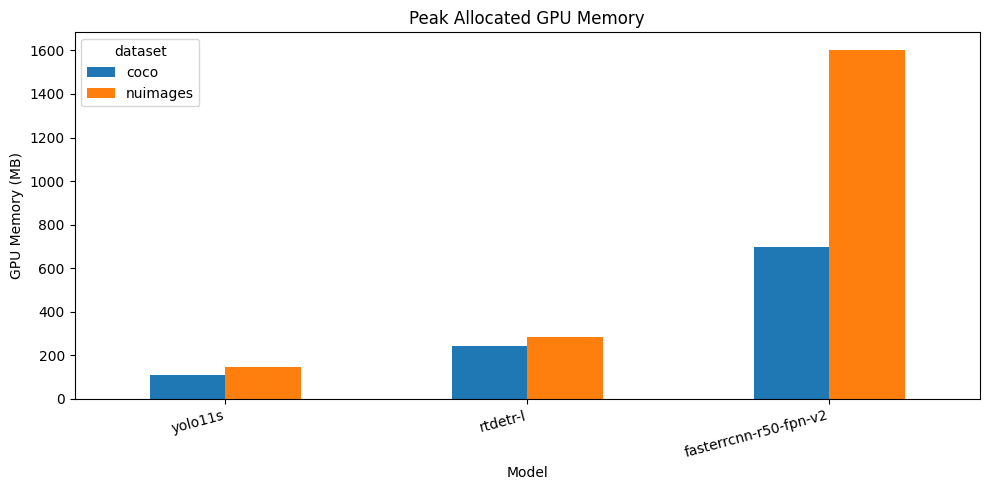


SECTION 6 COMPLETE
All comparative tables and figures saved to:
/content/drive/MyDrive/ColabNotebooks/detection_benchmark


In [ ]:
# ============================================================
# SECTION 6: CROSS-DATASET COMPARATIVE ANALYSIS
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# ------------------------------------------------------------
# 1. Load previously saved full evaluation results
# ------------------------------------------------------------

coco_summary_path = ROOT / 'full_summary.csv'
coco_perclass_path = ROOT / 'full_per_class_ap.csv'

nu_summary_path = ROOT / 'full_nuimages_summary.csv'
nu_perclass_path = ROOT / 'full_nuimages_per_class_ap.csv'

for path in [
    coco_summary_path,
    coco_perclass_path,
    nu_summary_path,
    nu_perclass_path
]:
    assert path.exists(), f"Missing file: {path}"

coco_summary = pd.read_csv(coco_summary_path)
coco_perclass = pd.read_csv(coco_perclass_path)

nu_summary = pd.read_csv(nu_summary_path)
nu_perclass = pd.read_csv(nu_perclass_path)

# Keep only the correct dataset from each saved file
coco_summary = coco_summary[
    coco_summary['dataset'] == 'coco'
].copy()

coco_perclass = coco_perclass[
    coco_perclass['dataset'] == 'coco'
].copy()

nu_summary = nu_summary[
    nu_summary['dataset'] == 'nuimages'
].copy()

nu_perclass = nu_perclass[
    nu_perclass['dataset'] == 'nuimages'
].copy()

# Combine results
combined_summary = pd.concat(
    [coco_summary, nu_summary],
    ignore_index=True
)

combined_perclass = pd.concat(
    [coco_perclass, nu_perclass],
    ignore_index=True
)

# Verify all six model-dataset combinations exist
expected_models = {
    'yolo11s',
    'rtdetr-l',
    'fasterrcnn-r50-fpn-v2'
}
expected_datasets = {'coco', 'nuimages'}

assert set(combined_summary['model']) == expected_models
assert set(combined_summary['dataset']) == expected_datasets

assert len(combined_summary) == 6, (
    "Expected 3 models evaluated on 2 datasets."
)

assert not combined_summary.duplicated(
    ['model', 'dataset']
).any(), "Duplicate model-dataset results found."

print("Combined full evaluation results:")
display(combined_summary.round(3))

# Save combined results
combined_summary.to_csv(
    ROOT / 'full_combined_summary.csv',
    index=False
)

combined_perclass.to_csv(
    ROOT / 'full_combined_per_class_ap.csv',
    index=False
)

# ------------------------------------------------------------
# 2. Cross-dataset mAP comparison
# ------------------------------------------------------------

model_order = [
    'yolo11s',
    'rtdetr-l',
    'fasterrcnn-r50-fpn-v2'
]
map_pivot = combined_summary.pivot(
    index='model',
    columns='dataset',
    values='mAP'
).reindex(model_order)

ax = map_pivot.plot(
    kind='bar',
    figsize=(10, 5)
)

ax.set_title(
    'Object Detection Accuracy Across Datasets'
)

ax.set_ylabel('mAP@[0.50:0.95]')
ax.set_xlabel('Model')
ax.set_ylim(0, 0.65)

plt.xticks(rotation=15, ha='right')
plt.legend(title='Dataset')
plt.tight_layout()

plt.savefig(
    ROOT / 'full_cross_dataset_map.png',
    dpi=200,
    bbox_inches='tight'
)

plt.show()

# ------------------------------------------------------------
# 3. Absolute and relative mAP changes
# ------------------------------------------------------------

map_changes = map_pivot.copy()

map_changes['absolute_change'] = (
    map_changes['nuimages']
    - map_changes['coco']
)

map_changes['relative_change_pct'] = (
    map_changes['absolute_change']
    / map_changes['coco']
) * 100

print("\nCross-dataset mAP changes:")
display(map_changes.round(3))

map_changes.to_csv(
    ROOT / 'full_domain_shift_map.csv'
)

# ------------------------------------------------------------
# 4. Per-class AP comparison
# ------------------------------------------------------------

perclass_pivot = combined_perclass.pivot_table(
    index=['model', 'class'],
    columns='dataset',
    values='AP'
)

perclass_pivot['absolute_change'] = (
    perclass_pivot['nuimages']
    - perclass_pivot['coco']
)

perclass_pivot['relative_change_pct'] = (
    perclass_pivot['absolute_change']
    / perclass_pivot['coco']
) * 100

print("\nPer-class cross-dataset AP changes:")

display(
    perclass_pivot.sort_values(
        'absolute_change'
    ).round(3)
)

perclass_pivot.to_csv(
    ROOT / 'full_domain_shift_by_class.csv'
)

# ------------------------------------------------------------
# 5. Per-class AP visualization
# ------------------------------------------------------------

for dataset in ['coco', 'nuimages']:

    subset = combined_perclass[
        combined_perclass['dataset'] == dataset
    ]

    class_pivot = subset.pivot(
        index='class',
        columns='model',
        values='AP'
    )

    class_pivot = class_pivot.reindex(
        columns=model_order
    )

    ax = class_pivot.plot(
        kind='bar',
        figsize=(11, 5)
    )

    ax.set_title(
        f'Per-Class Average Precision — {dataset.upper()}'
    )

    ax.set_ylabel('AP@[0.50:0.95]')
    ax.set_xlabel('Object Class')
    ax.set_ylim(0, 0.85)

    plt.xticks(rotation=30, ha='right')
    plt.legend(title='Model')
    plt.tight_layout()

    plt.savefig(
        ROOT / f'full_{dataset}_per_class_ap.png',
        dpi=200,
        bbox_inches='tight'
    )

    plt.show()

# ------------------------------------------------------------
# 6. Speed-accuracy tradeoff
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(9, 6))

for dataset in ['coco', 'nuimages']:

    subset = combined_summary[
        combined_summary['dataset'] == dataset
    ]

    for _, row in subset.iterrows():

        ax.scatter(
            row['latency_ms_median'],
            row['mAP'],
            s=110
        )

        ax.annotate(
            f"{row['model']} ({dataset})",
            (
                row['latency_ms_median'],
                row['mAP']
            ),
            xytext=(6, 6),
            textcoords='offset points',
            fontsize=8
        )

ax.set_xlabel('Median Inference Latency (ms)')
ax.set_ylabel('mAP@[0.50:0.95]')

ax.set_title(
    'Speed–Accuracy Tradeoff Across Datasets'
)

ax.grid(alpha=0.25)

plt.tight_layout()

plt.savefig(
    ROOT / 'full_speed_accuracy_tradeoff.png',
    dpi=200,
    bbox_inches='tight'
)

plt.show()

# ------------------------------------------------------------
# 7. GPU memory comparison
# ------------------------------------------------------------

memory_pivot = combined_summary.pivot(
    index='model',
    columns='dataset',
    values='peak_allocated_gpu_mb'
).reindex(model_order)

ax = memory_pivot.plot(
    kind='bar',
    figsize=(10, 5)
)

ax.set_title('Peak Allocated GPU Memory')
ax.set_ylabel('GPU Memory (MB)')
ax.set_xlabel('Model')

plt.xticks(rotation=15, ha='right')
plt.tight_layout()

plt.savefig(
    ROOT / 'full_gpu_memory_comparison.png',
    dpi=200,
    bbox_inches='tight'
)

plt.show()

# ------------------------------------------------------------
# 8. Final summary
# ------------------------------------------------------------

print("\nSECTION 6 COMPLETE")
print("All comparative tables and figures saved to:")
print(ROOT)

## 7. Failure analysis — saved predictions only

For a **reproducible fixed sample** of up to 250 images per dataset, classify detections using a **class-aware greedy IoU ≥ 0.50 match** and an **analysis-only score threshold of 0.25**. Export descriptive TP/FP/FN counts and examples with ground-truth and prediction boxes. This is **not** the official COCOeval AP procedure: COCO crowd/ignore handling and nuImages excluded/unannotated objects are not fully modeled. Treat apparent false positives as *unmatched detections under the custom six-class annotations*. No model inference is required. Images are displayed only when local image files exist.

In [ ]:
# ============================================================
# RESTORE NUIMAGES IMAGES FOR SECTION 7
# Extract only selected images from existing Drive archive.
# ============================================================

import tarfile
import pandas as pd
from pathlib import Path

archive = Path(
    '/content/drive/MyDrive/ColabNotebooks/nuimages/'
    'nuimages-v1.0-all-samples.tgz'
)

missing_csv = (
    ROOT / 'failure_analysis' /
    'nuimages_missing_images.csv'
)

output_root = Path('/content/datasets/nuimages')
output_root.mkdir(parents=True, exist_ok=True)

missing = pd.read_csv(missing_csv)

# Restore the top 10 highest-error candidate images.
selected = (
    missing.sort_values(
        'error_count',
        ascending=False
    )
    .head(10)
)

wanted = {
    str(path).replace('\\', '/').lstrip('./')
    for path in selected['relative_path']
}

restored = []
not_found = []

with tarfile.open(archive, 'r:gz') as tar:

    members = {}

    for member in tar:
        if not member.isfile():
            continue

        name = member.name.replace('\\', '/')
        name = name.lstrip('./')

        # Archive may have a leading folder.
        for rel in wanted:
            if name == rel or name.endswith('/' + rel):
                members[rel] = member

        if len(members) == len(wanted):
            break

    for rel in sorted(wanted):

        member = members.get(rel)

        if member is None:
            not_found.append(rel)
            continue

        destination = output_root / rel
        destination.parent.mkdir(
            parents=True,
            exist_ok=True
        )

        source = tar.extractfile(member)

        if source is None:
            not_found.append(rel)
            continue

        with source, open(destination, 'wb') as target:
            import shutil
            shutil.copyfileobj(source, target)

        restored.append(str(destination))

print('Restored:', len(restored))
print('Not found:', len(not_found))

for path in restored:
    print(path)

if not_found:
    print('\nMissing archive members:')
    for path in not_found[:10]:
        print(path)

Restored: 10
Not found: 0
/content/datasets/nuimages/samples/CAM_BACK/n006-2018-09-17-11-57-46-0400__CAM_BACK__1537200941937532.jpg
/content/datasets/nuimages/samples/CAM_BACK_LEFT/n015-2018-09-05-14-28-08+0800__CAM_BACK_LEFT__1536128955147423.jpg
/content/datasets/nuimages/samples/CAM_BACK_LEFT/n016-2018-09-05-11-08-19+0800__CAM_BACK_LEFT__1536116985397243.jpg
/content/datasets/nuimages/samples/CAM_BACK_LEFT/n016-2018-09-05-11-08-19+0800__CAM_BACK_LEFT__1536117029697243.jpg
/content/datasets/nuimages/samples/CAM_BACK_RIGHT/n008-2018-05-14-14-13-44-0400__CAM_BACK_RIGHT__1526321838277813.jpg
/content/datasets/nuimages/samples/CAM_BACK_RIGHT/n013-2018-08-02-15-07-28+0800__CAM_BACK_RIGHT__1533194321628054.jpg
/content/datasets/nuimages/samples/CAM_FRONT/n006-2018-09-17-11-57-46-0400__CAM_FRONT__1537199906862482.jpg
/content/datasets/nuimages/samples/CAM_FRONT/n006-2018-09-17-11-57-46-0400__CAM_FRONT__1537200749762482.jpg
/content/datasets/nuimages/samples/CAM_FRONT/n009-2018-07-12-16-12-5

In [ ]:
# ============================================================
# RESTORE COCO IMAGES — HTTP FALLBACK
# Downloads 10 images without rerunning inference.
# ============================================================

from pathlib import Path
from PIL import Image
from io import BytesIO
import pandas as pd
import requests
import time

missing_csv = ROOT / 'failure_analysis' / 'coco_missing_images.csv'
output_dir = COCO_DIR / 'val2017'
output_dir.mkdir(parents=True, exist_ok=True)

missing = pd.read_csv(missing_csv)

selected = (
    missing.sort_values('error_count', ascending=False)
    .head(10)
)

restored = []
failed = []

session = requests.Session()
session.trust_env = False  # Avoid inherited proxy settings, if any

for _, row in selected.iterrows():
    filename = Path(row['relative_path']).name
    destination = output_dir / filename

    url = f'http://images.cocodataset.org/val2017/{filename}'

    try:
        response = session.get(
            url,
            timeout=30,
            allow_redirects=True
        )
        response.raise_for_status()

        # Verify that the response is an actual image.
        image = Image.open(BytesIO(response.content))
        image.verify()

        destination.write_bytes(response.content)
        restored.append(filename)

    except Exception as e:
        failed.append((filename, str(e)))

    time.sleep(0.2)

print('Restored:', len(restored))
print('Failed:', len(failed))

for filename in restored:
    print(filename)

if failed:
    print('\nFailed downloads:')
    for filename, error in failed:
        print(filename, error)

Restored: 10
Failed: 0
000000439994.jpg
000000039405.jpg
000000211674.jpg
000000134322.jpg
000000312237.jpg
000000107851.jpg
000000199236.jpg
000000016228.jpg
000000457848.jpg
000000540414.jpg



Descriptive sample-level matching (NOT official COCO metrics):


,dataset,model,tp,fp,fn,sample_precision,sample_recall
0,coco,fasterrcnn-r50-fpn-v2,539,670,94,0.446,0.852
1,coco,rtdetr-l,520,546,113,0.488,0.821
2,coco,yolo11s,386,98,247,0.798,0.610
3,nuimages,fasterrcnn-r50-fpn-v2,969,1078,446,0.473,0.685
4,nuimages,rtdetr-l,828,1008,587,0.451,0.585
5,nuimages,yolo11s,543,209,872,0.722,0.384



Per-class failure analysis:


,dataset,model,class,sample_images,score_threshold,iou_threshold,tp,fp,fn,precision_sample,recall_sample
0,coco,yolo11s,person,250,0.25,0.5,315,74,187,0.810,0.627
1,coco,yolo11s,car,250,0.25,0.5,46,13,43,0.780,0.517
2,coco,yolo11s,truck,250,0.25,0.5,8,5,9,0.615,0.471
3,coco,yolo11s,bus,250,0.25,0.5,7,2,3,0.778,0.700
4,coco,yolo11s,bicycle,250,0.25,0.5,2,1,3,0.667,0.400
5,coco,yolo11s,motorcycle,250,0.25,0.5,8,3,2,0.727,0.800
6,coco,rtdetr-l,person,250,0.25,0.5,419,411,83,0.505,0.835
7,coco,rtdetr-l,car,250,0.25,0.5,67,79,22,0.459,0.753
8,coco,rtdetr-l,truck,250,0.25,0.5,14,23,3,0.378,0.824
9,coco,rtdetr-l,bus,250,0.25,0.5,7,4,3,0.636,0.700



COCO: 10 available images; 82 missing candidate images.


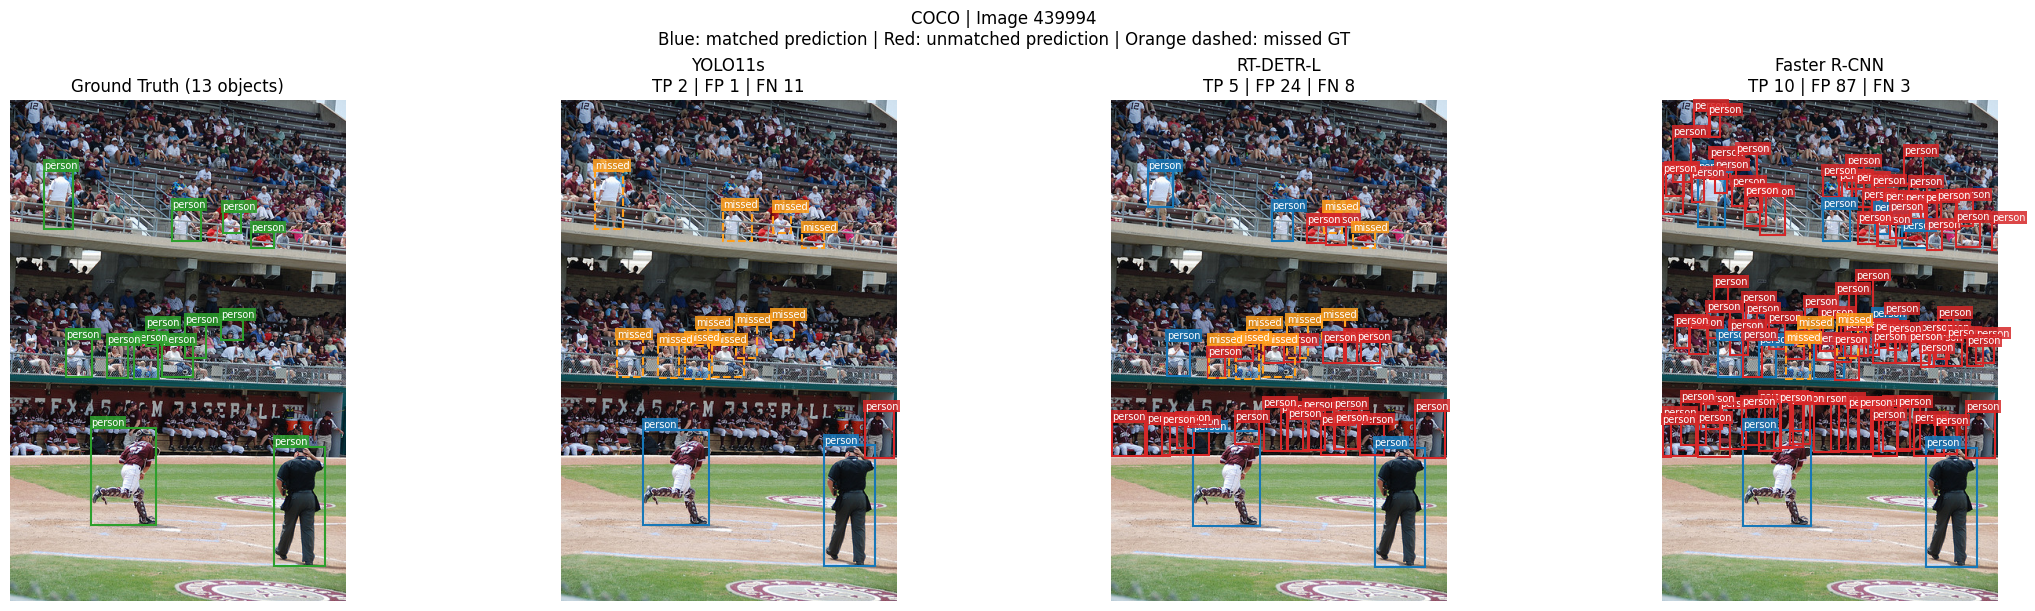

Saved: /content/drive/MyDrive/ColabNotebooks/detection_benchmark/failure_analysis/coco_failure_example_1.png


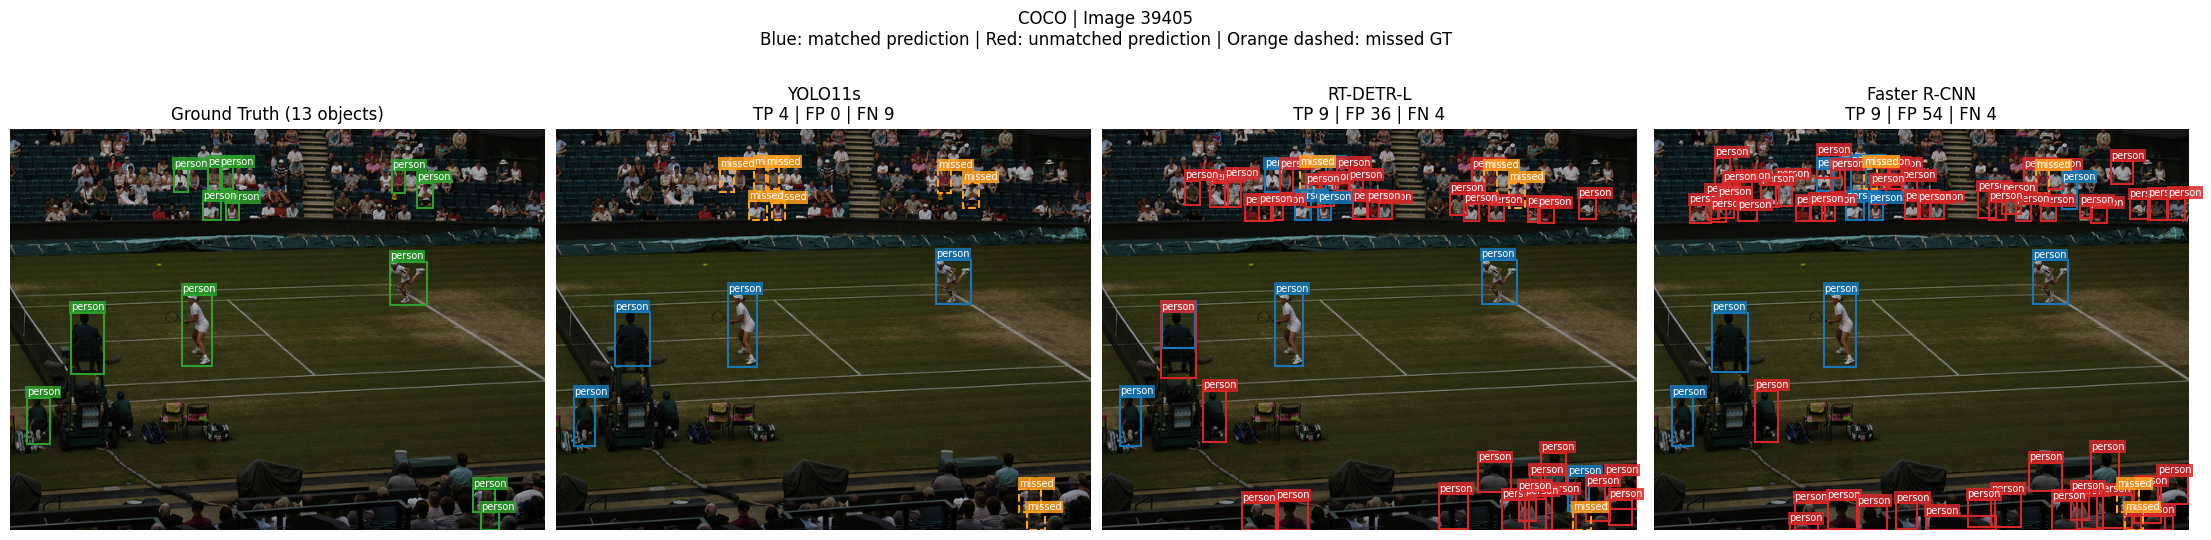

Saved: /content/drive/MyDrive/ColabNotebooks/detection_benchmark/failure_analysis/coco_failure_example_2.png


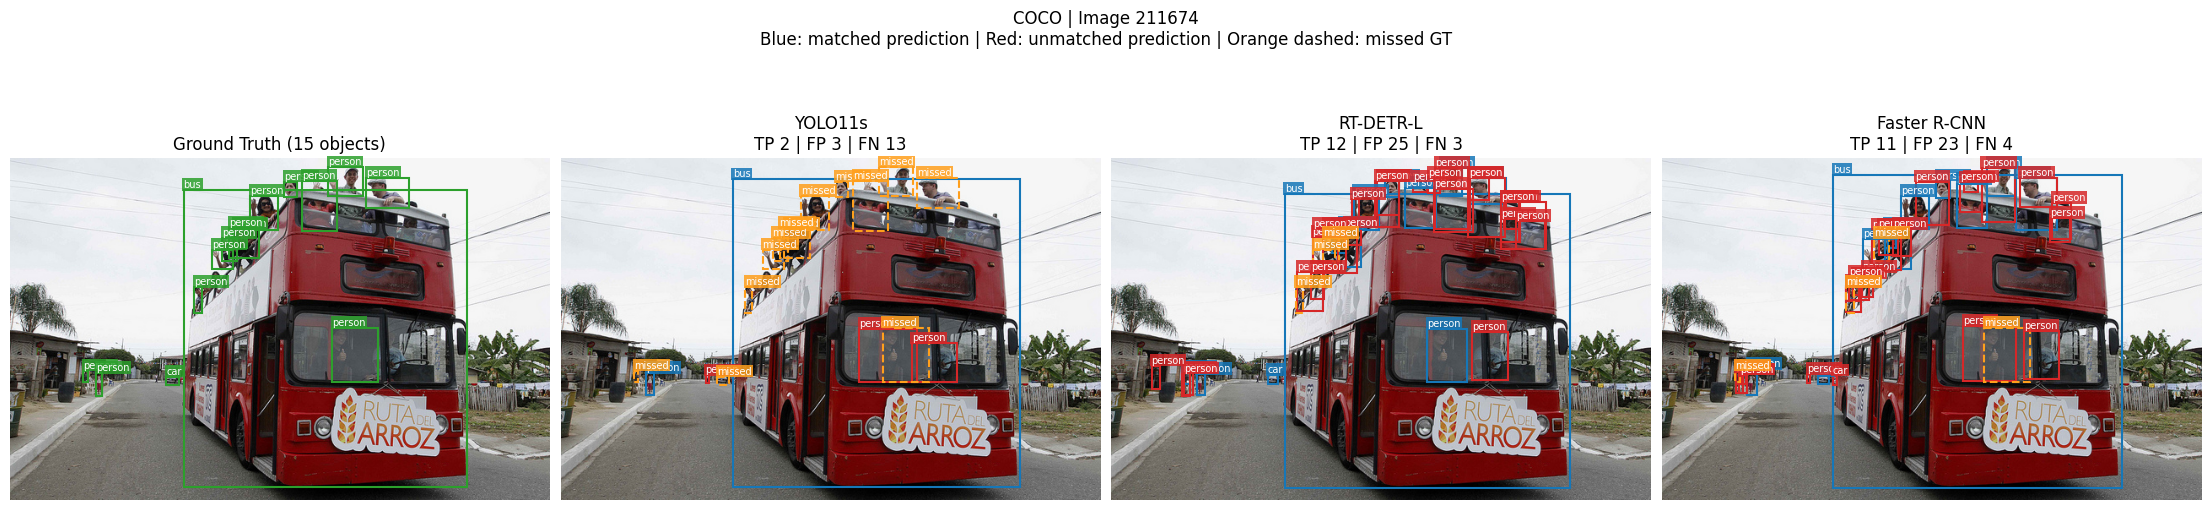

Saved: /content/drive/MyDrive/ColabNotebooks/detection_benchmark/failure_analysis/coco_failure_example_3.png

NUIMAGES: 10 available images; 163 missing candidate images.


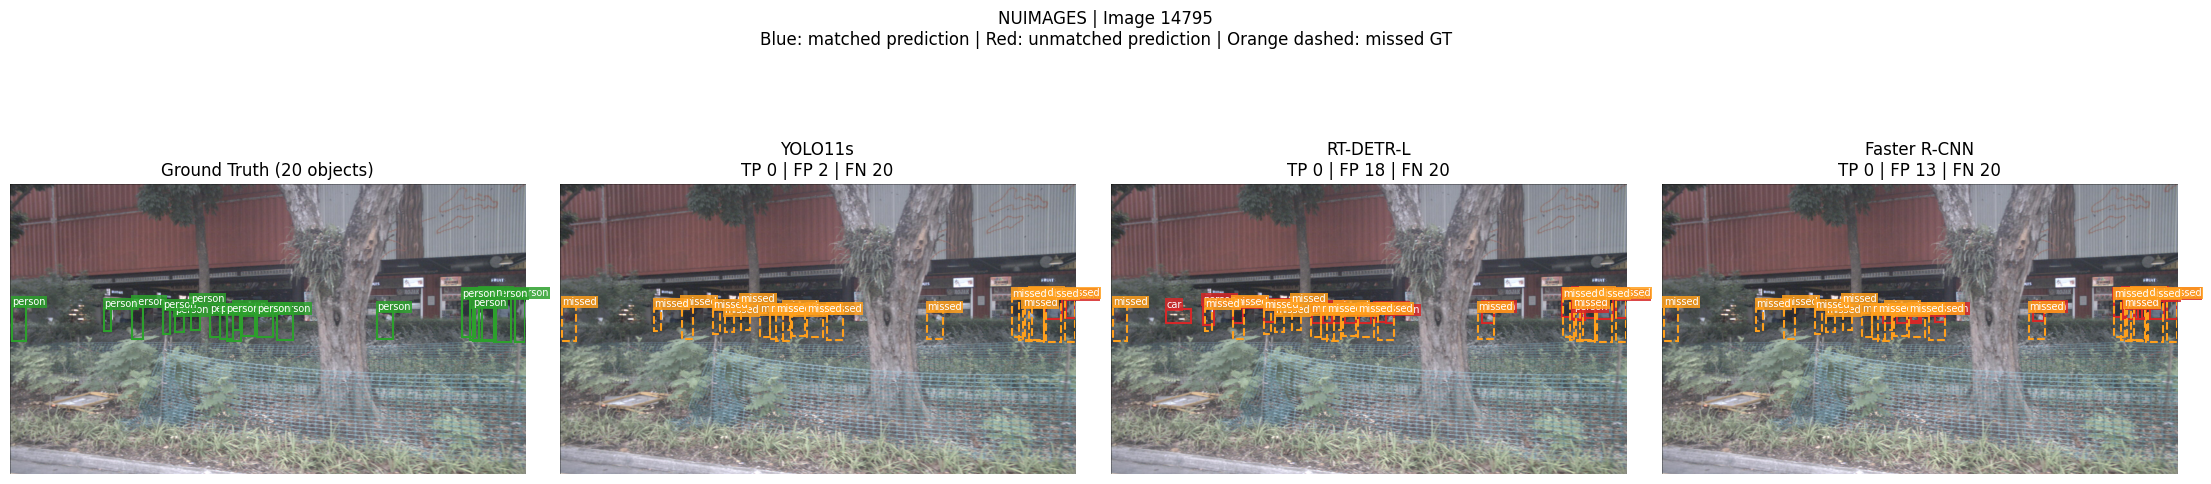

Saved: /content/drive/MyDrive/ColabNotebooks/detection_benchmark/failure_analysis/nuimages_failure_example_1.png


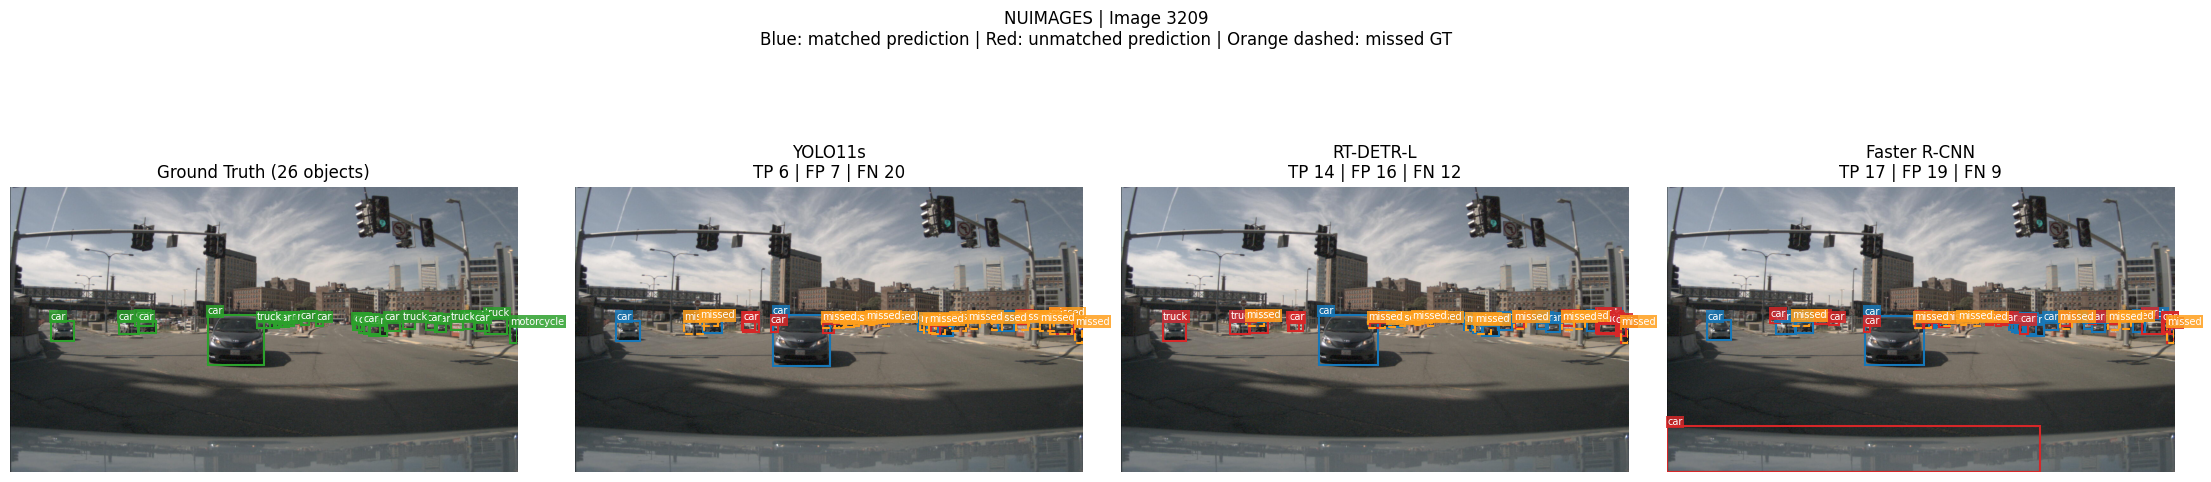

Saved: /content/drive/MyDrive/ColabNotebooks/detection_benchmark/failure_analysis/nuimages_failure_example_2.png


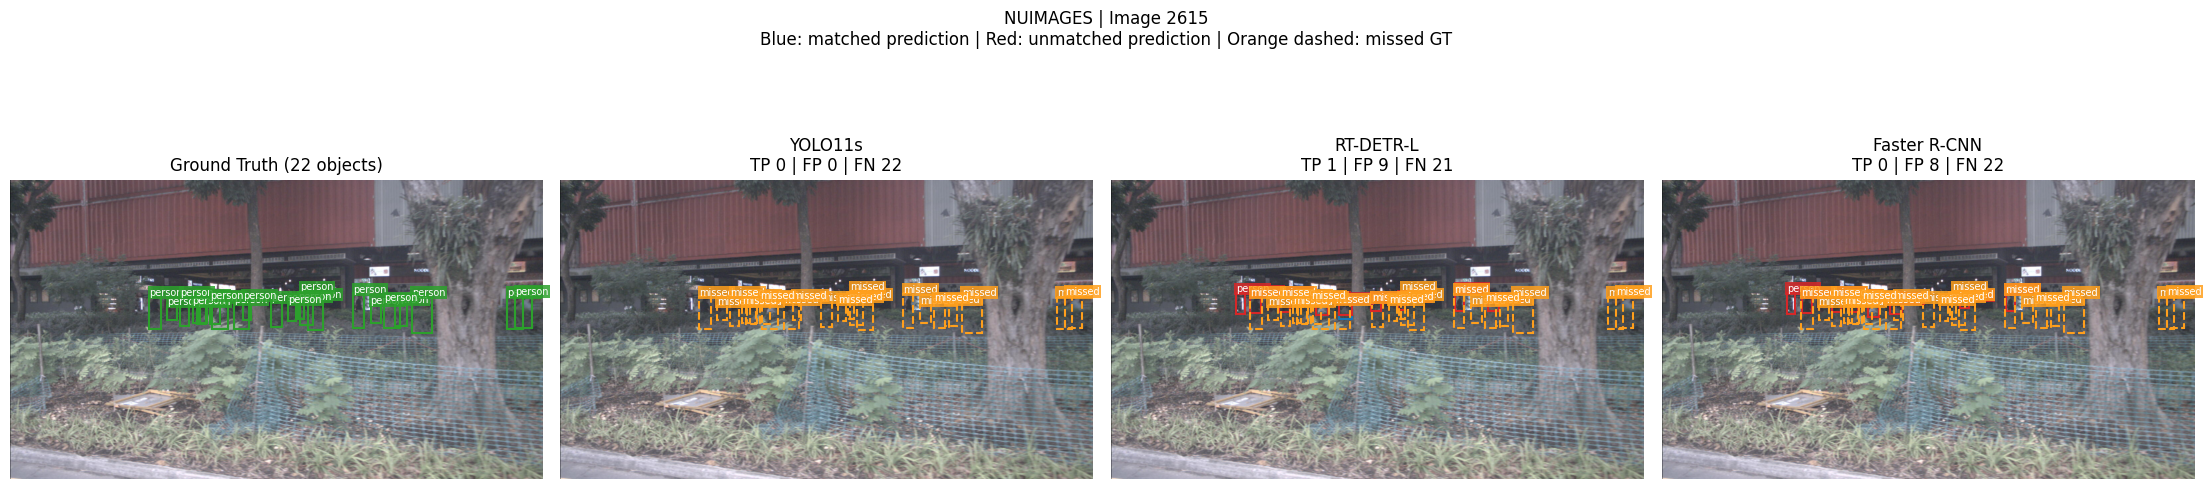

Saved: /content/drive/MyDrive/ColabNotebooks/detection_benchmark/failure_analysis/nuimages_failure_example_3.png

SECTION 7 COMPLETE
Output directory: /content/drive/MyDrive/ColabNotebooks/detection_benchmark/failure_analysis

Saved quantitative outputs:
- sample_failure_counts_by_model.csv
- sample_failure_counts_by_class.csv
- failure_analysis_config.json

Visualization outputs:
- coco: 3 figure file(s) found
- nuimages: 3 figure file(s) found

Note: TP/FP/FN statistics are descriptive sample-based results, not official COCO metrics.


In [ ]:
# ============================================================
# SECTION 7: QUANTITATIVE + QUALITATIVE FAILURE ANALYSIS
# Uses saved ground truth and predictions; NO inference needed.
# ============================================================

from collections import defaultdict
from matplotlib.patches import Rectangle
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import json
import random

# ------------------------------------------------------------
# 7.1 Configuration
# ------------------------------------------------------------

CLASSES = [
    'person', 'car', 'truck',
    'bus', 'bicycle', 'motorcycle'
]

MODEL_KEYS = [
    'yolo11s',
    'rtdetr-l',
    'fasterrcnn-r50-fpn-v2'
]

MODEL_LABELS = {
    'yolo11s': 'YOLO11s',
    'rtdetr-l': 'RT-DETR-L',
    'fasterrcnn-r50-fpn-v2': 'Faster R-CNN'
}

FAILURE_SAMPLE_SIZE = 250
FAILURE_SCORE = 0.25
FAILURE_IOU = 0.50
FAILURE_SEED = 42

MAX_EXAMPLES_PER_DATASET = 3

FAILURE_DIR = ROOT / 'failure_analysis'
FAILURE_DIR.mkdir(parents=True, exist_ok=True)

DATASETS = {
    'coco': COCO_DIR / 'val2017',
    'nuimages': NUIMAGES_ROOT
}

COLORS = {
    'gt': '#2ca02c',
    'tp': '#1677b8',
    'fp': '#d62728',
    'fn': '#ff9f1c'
}

# Save analysis settings for reproducibility.
analysis_config = {
    'sample_size_per_dataset': FAILURE_SAMPLE_SIZE,
    'score_threshold': FAILURE_SCORE,
    'iou_threshold': FAILURE_IOU,
    'random_seed': FAILURE_SEED,
    'models': MODEL_KEYS,
    'classes': CLASSES,
    'max_examples_per_dataset': MAX_EXAMPLES_PER_DATASET,
    'matching': 'Class-aware, score-ordered greedy matching',
    'note': (
        'Descriptive sample-level analysis, not official '
        'COCO AP/AR evaluation.'
    )
}

(FAILURE_DIR / 'failure_analysis_config.json').write_text(
    json.dumps(analysis_config, indent=2)
)

# ------------------------------------------------------------
# 7.2 IoU and prediction matching
# ------------------------------------------------------------

def bbox_iou_xywh(a, b):
    ax, ay, aw, ah = map(float, a)
    bx, by, bw, bh = map(float, b)

    x1 = max(ax, bx)
    y1 = max(ay, by)
    x2 = min(ax + aw, bx + bw)
    y2 = min(ay + ah, by + bh)

    intersection = max(0., x2 - x1) * max(0., y2 - y1)
    union = aw * ah + bw * bh - intersection

    return intersection / union if union > 0 else 0.


def match_image(gts, preds):
    """
    Class-aware, score-ordered greedy matching.

    TP: prediction matched to unused same-class GT at IoU >= 0.50
    FP: unmatched prediction above confidence threshold
    FN: unmatched GT annotation

    This is a descriptive analysis, not COCOeval.
    """

    preds = sorted(
        [
            p for p in preds
            if p['score'] >= FAILURE_SCORE
        ],
        key=lambda p: p['score'],
        reverse=True
    )

    used = set()
    matches = []
    false_pos = []

    for p in preds:
        best_idx = None
        best_iou = FAILURE_IOU

        for i, g in enumerate(gts):
            if i in used:
                continue

            if p['category_id'] != g['category_id']:
                continue

            iou = bbox_iou_xywh(
                p['bbox'],
                g['bbox']
            )

            if iou >= best_iou:
                best_iou = iou
                best_idx = i

        if best_idx is None:
            false_pos.append(p)
        else:
            used.add(best_idx)
            matches.append(
                (p, gts[best_idx], best_iou)
            )

    missed = [
        g for i, g in enumerate(gts)
        if i not in used
    ]

    return matches, false_pos, missed


# ------------------------------------------------------------
# 7.3 Load saved results and compute failure statistics
# ------------------------------------------------------------

failure_rows = []
figure_candidates = {}

for ds, image_root in DATASETS.items():

    gt_path = ROOT / f'{ds}_gt_full.json'

    if not gt_path.exists():
        print('Skipping dataset without GT:', gt_path)
        continue

    gt = json.loads(gt_path.read_text())

    images = {
        im['id']: im
        for im in gt['images']
    }

    gt_by_image = defaultdict(list)

    for ann in gt['annotations']:
        if ann.get('iscrowd', 0):
            continue

        gt_by_image[ann['image_id']].append(ann)

    sample_ids = sorted(
        random.Random(FAILURE_SEED).sample(
            list(images),
            min(FAILURE_SAMPLE_SIZE, len(images))
        )
    )

    figure_candidates[ds] = {}

    for model_key in MODEL_KEYS:

        pred_path = (
            ROOT /
            f'full_{ds}_{model_key}_predictions.json'
        )

        if not pred_path.exists():
            print('Missing predictions:', pred_path.name)
            continue

        preds_by_image = defaultdict(list)

        for pred in json.loads(pred_path.read_text()):
            if pred['image_id'] in sample_ids:
                preds_by_image[pred['image_id']].append(pred)

        totals = defaultdict(
            lambda: {'tp': 0, 'fp': 0, 'fn': 0}
        )

        cases = []

        for iid in sample_ids:

            matches, fp, fn = match_image(
                gt_by_image[iid],
                preds_by_image[iid]
            )

            for _, g, _ in matches:
                totals[g['category_id']]['tp'] += 1

            for p in fp:
                totals[p['category_id']]['fp'] += 1

            for g in fn:
                totals[g['category_id']]['fn'] += 1

            cases.append({
                'image_id': iid,
                'tp': len(matches),
                'fp': len(fp),
                'fn': len(fn),
                'error_total': len(fp) + len(fn)
            })

        for class_id, class_name in enumerate(CLASSES, 1):

            t = totals[class_id]

            precision = (
                t['tp'] / (t['tp'] + t['fp'])
                if t['tp'] + t['fp'] > 0
                else np.nan
            )

            recall = (
                t['tp'] / (t['tp'] + t['fn'])
                if t['tp'] + t['fn'] > 0
                else np.nan
            )

            failure_rows.append({
                'dataset': ds,
                'model': model_key,
                'class': class_name,
                'sample_images': len(sample_ids),
                'score_threshold': FAILURE_SCORE,
                'iou_threshold': FAILURE_IOU,
                **t,
                'precision_sample': precision,
                'recall_sample': recall
            })

        figure_candidates[ds][model_key] = {
            'cases': cases,
            'preds': preds_by_image,
            'gt': gt_by_image,
            'images': images,
            'root': Path(image_root)
        }


# ------------------------------------------------------------
# 7.4 Save quantitative results
# ------------------------------------------------------------

failure_df = pd.DataFrame(failure_rows)

if failure_df.empty:
    print('No saved GT/prediction pairs were found.')

else:

    failure_df.to_csv(
        FAILURE_DIR / 'sample_failure_counts_by_class.csv',
        index=False
    )

    aggregate = (
        failure_df
        .groupby(['dataset', 'model'], as_index=False)
        [['tp', 'fp', 'fn']]
        .sum()
    )

    aggregate['sample_precision'] = (
        aggregate.tp /
        (aggregate.tp + aggregate.fp)
    )

    aggregate['sample_recall'] = (
        aggregate.tp /
        (aggregate.tp + aggregate.fn)
    )

    aggregate.to_csv(
        FAILURE_DIR / 'sample_failure_counts_by_model.csv',
        index=False
    )

    print(
        '\nDescriptive sample-level matching '
        '(NOT official COCO metrics):'
    )

    display(aggregate.round(3))

    print('\nPer-class failure analysis:')
    display(failure_df.round(3))


# ------------------------------------------------------------
# 7.5 Visualization helper
# ------------------------------------------------------------

def draw_xywh(
    ax,
    box,
    color,
    label,
    linestyle='-',
    lw=1.5
):

    x, y, w, h = map(float, box)

    ax.add_patch(
        Rectangle(
            (x, y),
            w,
            h,
            fill=False,
            edgecolor=color,
            linewidth=lw,
            linestyle=linestyle
        )
    )

    if label:
        ax.text(
            x,
            max(0, y - 3),
            label,
            color='white',
            fontsize=7,
            bbox=dict(
                facecolor=color,
                edgecolor='none',
                alpha=0.85,
                pad=1
            )
        )


# ------------------------------------------------------------
# 7.6 Select available images and generate comparisons
# ------------------------------------------------------------

for ds, by_model in figure_candidates.items():

    if len(by_model) != len(MODEL_KEYS):
        print(
            f'{ds}: incomplete model results; '
            'skipping visual comparison.'
        )
        continue

    info = by_model[MODEL_KEYS[0]]

    candidates = defaultdict(int)

    for model_key in MODEL_KEYS:
        for case in by_model[model_key]['cases']:
            candidates[case['image_id']] += (
                case['error_total']
            )

    # Prefer images with at least two GT objects.
    ranked = sorted(
        [
            (iid, error_count)
            for iid, error_count in candidates.items()
            if len(info['gt'][iid]) >= 2
        ],
        key=lambda item: (-item[1], item[0])
    )

    available = []
    missing = []

    for iid, error_count in ranked:

        rel_path = info['images'][iid]['file_name']
        image_path = info['root'] / rel_path

        if image_path.is_file():
            available.append(
                (iid, image_path, error_count)
            )
        else:
            missing.append({
                'image_id': iid,
                'relative_path': rel_path,
                'expected_path': str(image_path),
                'error_count': error_count
            })

    missing_columns = [
        'image_id',
        'relative_path',
        'expected_path',
        'error_count'
    ]

    pd.DataFrame(
        missing,
        columns=missing_columns
    ).to_csv(
        FAILURE_DIR / f'{ds}_missing_images.csv',
        index=False
    )

    print(
        f'\n{ds.upper()}: '
        f'{len(available)} available images; '
        f'{len(missing)} missing candidate images.'
    )

    if not available:
        print(
            f'{ds}: no visualizations generated. '
            'Restore source images and rerun Section 7.'
        )
        continue

    for example_num, (
        iid,
        image_path,
        error_count
    ) in enumerate(
        available[:MAX_EXAMPLES_PER_DATASET],
        start=1
    ):

        with Image.open(image_path) as im:
            rgb = im.convert('RGB')

        gts = info['gt'][iid]

        fig, axes = plt.subplots(
            1,
            4,
            figsize=(22, 6),
            constrained_layout=True
        )

        for ax in axes:
            ax.imshow(rgb)
            ax.axis('off')

        # Ground-truth panel
        for g in gts:
            draw_xywh(
                axes[0],
                g['bbox'],
                COLORS['gt'],
                CLASSES[g['category_id'] - 1]
            )

        axes[0].set_title(
            f'Ground Truth ({len(gts)} objects)'
        )

        # Three model comparison panels
        for ax, model_key in zip(
            axes[1:],
            MODEL_KEYS
        ):

            matches, fp, fn = match_image(
                gts,
                by_model[model_key]['preds'][iid]
            )

            for p, g, iou in matches:
                draw_xywh(
                    ax,
                    p['bbox'],
                    COLORS['tp'],
                    CLASSES[p['category_id'] - 1]
                )

            for p in fp:
                draw_xywh(
                    ax,
                    p['bbox'],
                    COLORS['fp'],
                    CLASSES[p['category_id'] - 1]
                )

            for g in fn:
                draw_xywh(
                    ax,
                    g['bbox'],
                    COLORS['fn'],
                    'missed',
                    linestyle='--'
                )

            ax.set_title(
                f'{MODEL_LABELS[model_key]}\n'
                f'TP {len(matches)} | '
                f'FP {len(fp)} | '
                f'FN {len(fn)}'
            )

        fig.suptitle(
            f'{ds.upper()} | Image {iid}\n'
            'Blue: matched prediction | '
            'Red: unmatched prediction | '
            'Orange dashed: missed GT',
            fontsize=12
        )

        output_path = (
            FAILURE_DIR /
            f'{ds}_failure_example_{example_num}.png'
        )

        fig.savefig(
            output_path,
            dpi=170,
            bbox_inches='tight'
        )

        plt.show()
        plt.close(fig)

        print('Saved:', output_path)


# ------------------------------------------------------------
# 7.7 Completion summary
# ------------------------------------------------------------

print('\n' + '=' * 55)
print('SECTION 7 COMPLETE')
print('=' * 55)

print('Output directory:', FAILURE_DIR)

print('\nSaved quantitative outputs:')
print('- sample_failure_counts_by_model.csv')
print('- sample_failure_counts_by_class.csv')
print('- failure_analysis_config.json')

print('\nVisualization outputs:')
for ds in DATASETS:
    figures = sorted(
        FAILURE_DIR.glob(
            f'{ds}_failure_example_*.png'
        )
    )
    print(f'- {ds}: {len(figures)} figure file(s) found')

print(
    '\nNote: TP/FP/FN statistics are descriptive '
    'sample-based results, not official COCO metrics.'
)
